# Notebook 9 – Categorical Data Analysis
## Objective
Analyze unique categories, frequencies, percentages, rare categories, cardinality, imbalance, and relationships between categorical variables and the target where applicable.

## 1. Load dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
sns.set_theme(style="whitegrid")
DATA_PATH = Path("WA_Fn-UseC_-Telco-Customer-Churn.csv")
DATA_PATH = Path( r"C:\Users\ramki\sprint_4\dataset\WA_Fn-UseC_-Telco-Customer-Churn.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"CSV not found at {DATA_PATH.resolve()}. Put the CSV beside this notebook or update DATA_PATH.")
df = pd.read_csv(DATA_PATH)
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Shape:", df.shape)
display(df.head())

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Identify categorical variables

In [2]:
categorical_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
print(categorical_cols)
display(df[categorical_cols].head())

['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


C:\Users\ramki\AppData\Local\Temp\ipykernel_13380\750235624.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
0,7590-VHVEG,Female,Yes,No,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,No
1,5575-GNVDE,Male,No,No,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,No
2,3668-QPYBK,Male,No,No,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,Yes
3,7795-CFOCW,Male,No,No,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),No
4,9237-HQITU,Female,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,Yes


## 3. Unique categories and cardinality
**Cardinality** means the number of distinct values. Low-cardinality variables have few categories; high-cardinality variables have many. IDs such as customerID are high-cardinality but usually should not be analyzed like ordinary categories.

In [3]:
rows = []
for col in categorical_cols:
    rows.append({"Variable": col, "Unique categories": df[col].nunique(),
                 "Missing count": df[col].isna().sum(),
                 "Missing %": round(df[col].isna().mean()*100, 2)})
display(pd.DataFrame(rows).set_index("Variable").sort_values("Unique categories", ascending=False))

,Unique categories,Missing count,Missing %
Variable,,,
customerID,7043,0,0.0
PaymentMethod,4,0,0.0
OnlineBackup,3,0,0.0
InternetService,3,0,0.0
OnlineSecurity,3,0,0.0
TechSupport,3,0,0.0
StreamingTV,3,0,0.0
DeviceProtection,3,0,0.0
MultipleLines,3,0,0.0


## 4. Category frequencies and percentages

In [4]:
for col in categorical_cols:
    counts = df[col].value_counts(dropna=False)
    pct = df[col].value_counts(normalize=True, dropna=False)*100
    print(f"\n{col}")
    display(pd.DataFrame({"Frequency": counts, "Percentage": pct.round(2)}))


customerID


,Frequency,Percentage
customerID,,
7590-VHVEG,1,0.01
5575-GNVDE,1,0.01
3668-QPYBK,1,0.01
7795-CFOCW,1,0.01
9237-HQITU,1,0.01
...,...,...
6840-RESVB,1,0.01
2234-XADUH,1,0.01
4801-JZAZL,1,0.01



gender


,Frequency,Percentage
gender,,
Male,3555,50.48
Female,3488,49.52



Partner


...

,Frequency,Percentage
PaperlessBilling,,
Yes,4171,59.22
No,2872,40.78



PaymentMethod


,Frequency,Percentage
PaymentMethod,,
Electronic check,2365,33.58
Mailed check,1612,22.89
Bank transfer (automatic),1544,21.92
Credit card (automatic),1522,21.61



Churn


,Frequency,Percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


## 5. Plot category frequencies
High-cardinality identifiers are excluded so the plots remain readable.

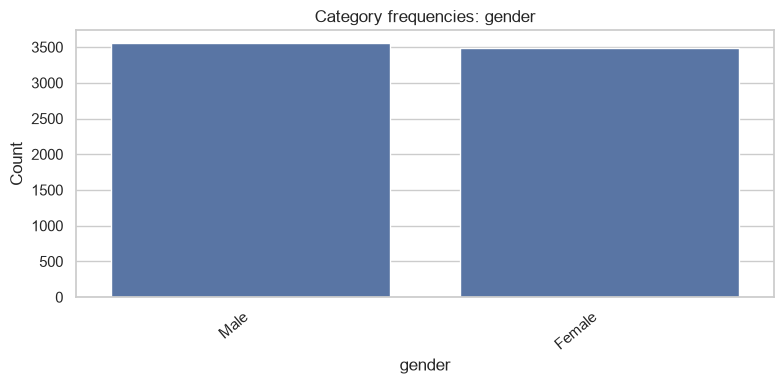

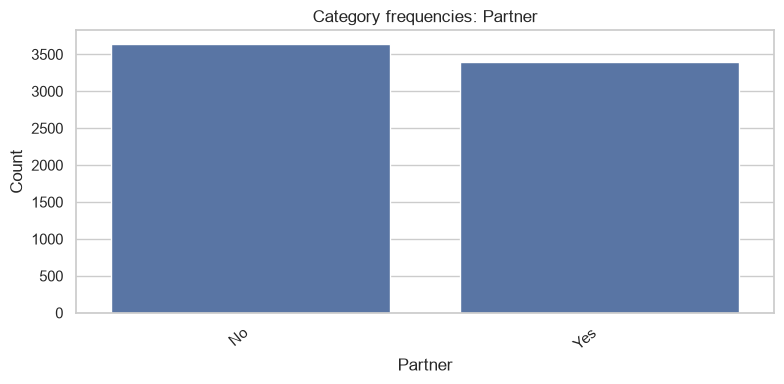

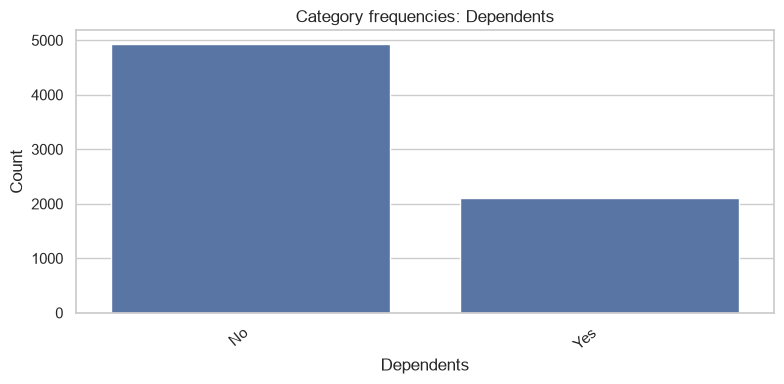

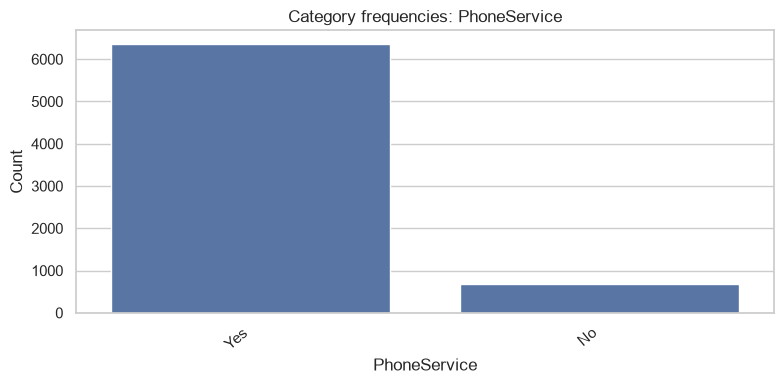

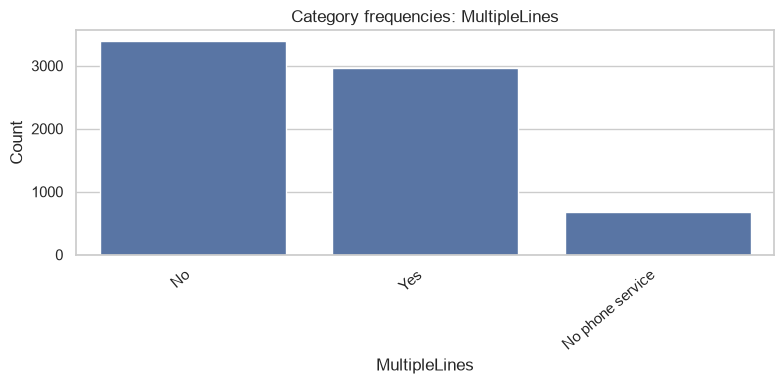

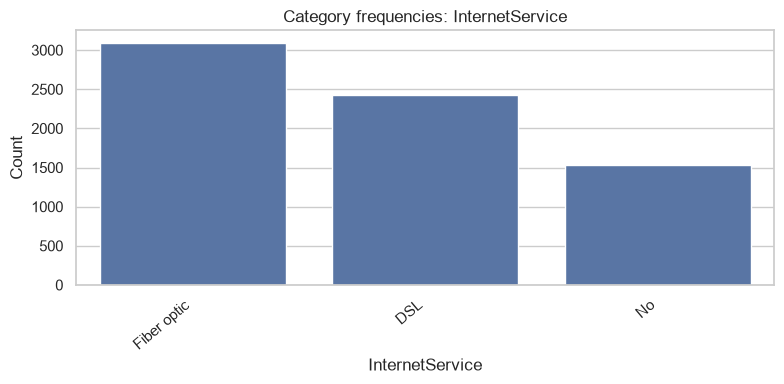

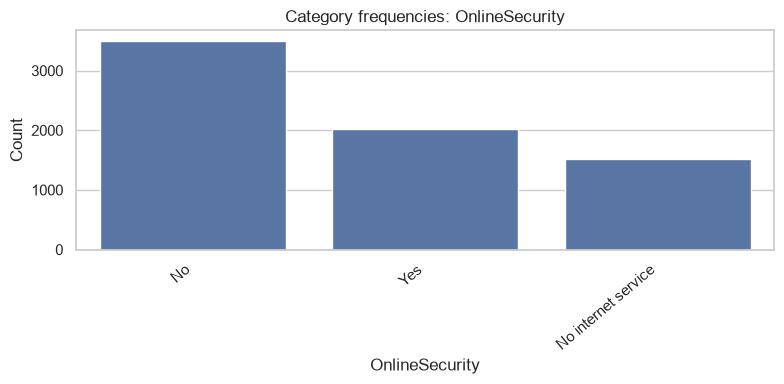

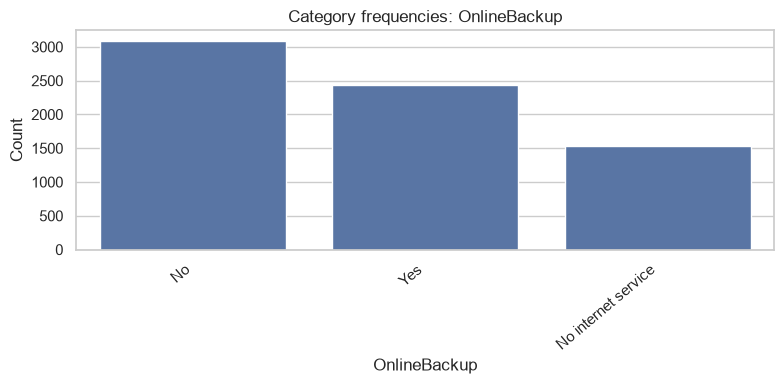

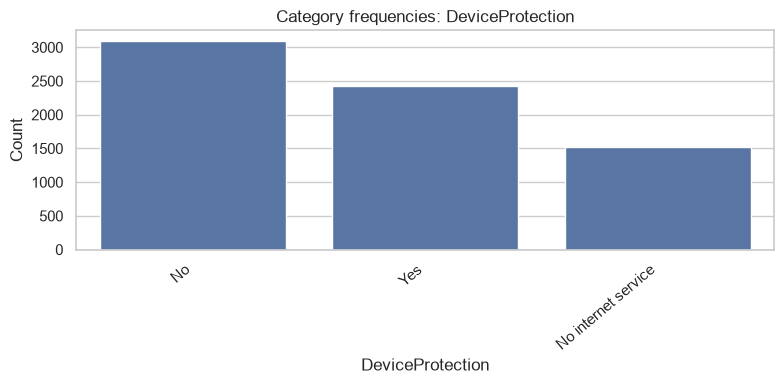

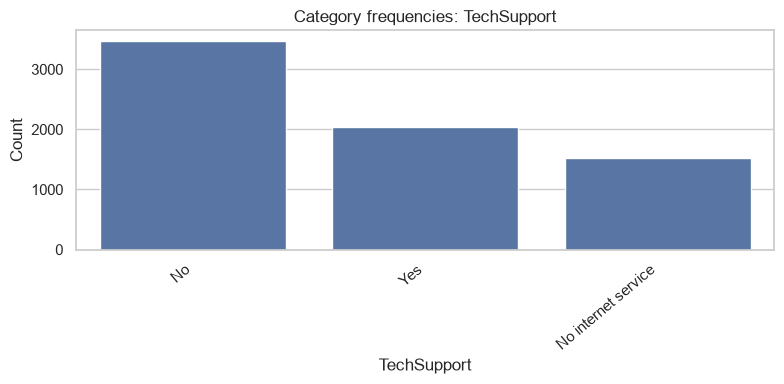

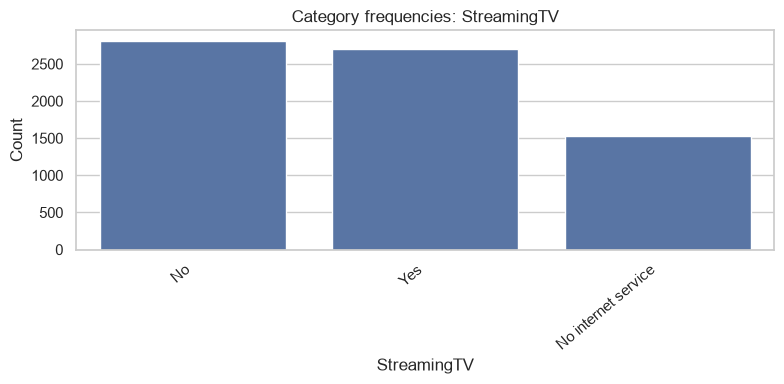

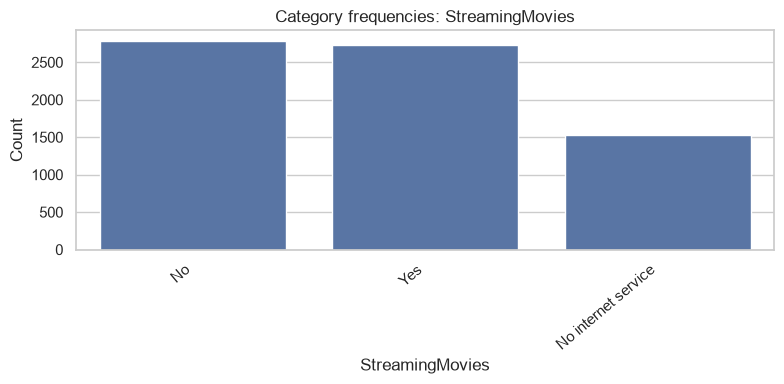

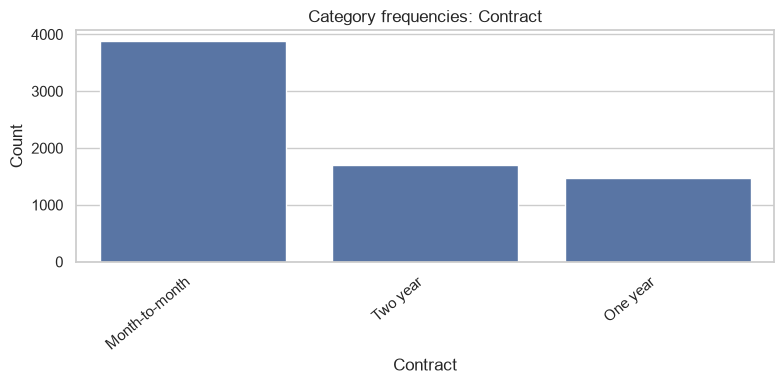

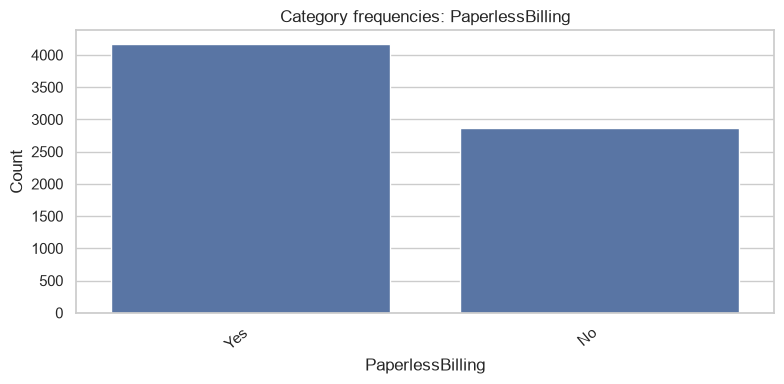

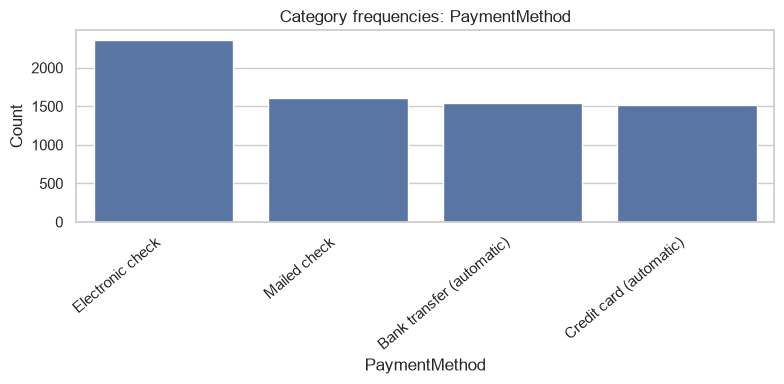

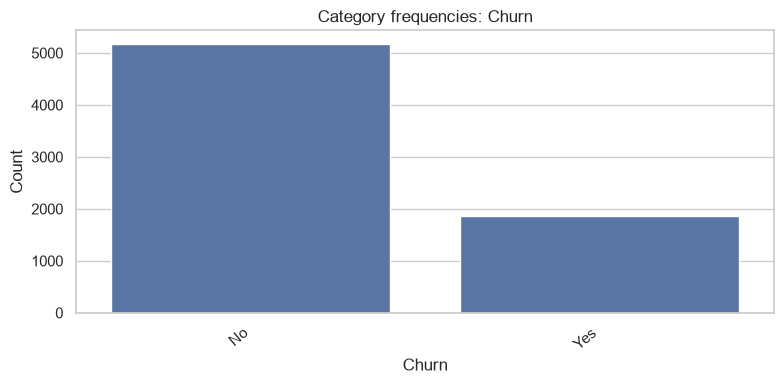

In [5]:
plot_cols = [c for c in categorical_cols
             if c.lower() not in {"customerid", "customer_id"}
             and df[c].nunique(dropna=True) <= 20]
for col in plot_cols:
    counts = df[col].value_counts(dropna=False)
    plt.figure(figsize=(8, 4))
    sns.barplot(x=counts.index.astype(str), y=counts.values)
    plt.title(f"Category frequencies: {col}")
    plt.xlabel(col); plt.ylabel("Count")
    plt.xticks(rotation=40, ha="right")
    plt.tight_layout(); plt.show()

## 6. Rare categories
For this example, a category below 1% of non-missing observations is flagged as rare. The threshold is context-dependent.

In [6]:
threshold_pct = 1.0
for col in categorical_cols:
    if col.lower() in {"customerid", "customer_id"}: continue
    pct = df[col].value_counts(normalize=True, dropna=True)*100
    rare = pct[pct < threshold_pct]
    print(f"\n{col}: rare categories below {threshold_pct}%")
    display(rare.to_frame("Percentage"))


gender: rare categories below 1.0%


,Percentage
gender,



Partner: rare categories below 1.0%


,Percentage
Partner,



Dependents: rare categories below 1.0%


...

,Percentage
PaperlessBilling,



PaymentMethod: rare categories below 1.0%


,Percentage
PaymentMethod,



Churn: rare categories below 1.0%


,Percentage
Churn,


**Interpretation:** Rare categories may be valid, erroneous, or important edge cases. Do not automatically delete or combine them; consider context and model requirements.

## 7. Category imbalance

In [7]:
rows = []
for col in categorical_cols:
    if col.lower() in {"customerid", "customer_id"}: continue
    counts = df[col].value_counts(dropna=True)
    if counts.empty: continue
    rows.append({"Variable": col, "Category count": df[col].nunique(),
                 "Most common category": str(counts.index[0]),
                 "Most common count": int(counts.iloc[0]),
                 "Most common %": round(counts.iloc[0]/counts.sum()*100, 2),
                 "Least common count": int(counts.iloc[-1])})
display(pd.DataFrame(rows).set_index("Variable"))

,Category count,Most common category,Most common count,Most common %,Least common count
Variable,,,,,
gender,2,Male,3555,50.48,3488
Partner,2,No,3641,51.70,3402
Dependents,2,No,4933,70.04,2110
PhoneService,2,Yes,6361,90.32,682
MultipleLines,3,No,3390,48.13,682
InternetService,3,Fiber optic,3096,43.96,1526
OnlineSecurity,3,No,3498,49.67,1526
OnlineBackup,3,No,3088,43.84,1526
DeviceProtection,3,No,3095,43.94,1526


## 8. Categorical features vs target (Churn)
Cross-tabulation and row percentages compare churn composition across categories.


Counts: gender vs Churn


Churn,No,Yes,All
gender,,,
Female,2549,939,3488
Male,2625,930,3555
All,5174,1869,7043


Row percentages:


Churn,No,Yes
gender,,
Female,73.08,26.92
Male,73.84,26.16


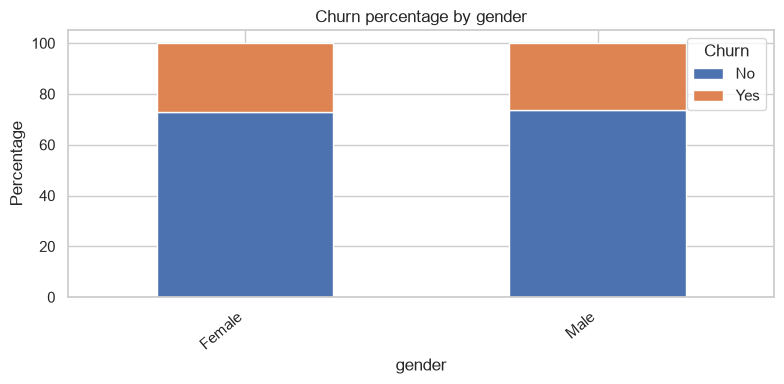


Counts: Partner vs Churn


Churn,No,Yes,All
Partner,,,
No,2441,1200,3641
Yes,2733,669,3402
All,5174,1869,7043


Row percentages:


Churn,No,Yes
Partner,,
No,67.04,32.96
Yes,80.34,19.66


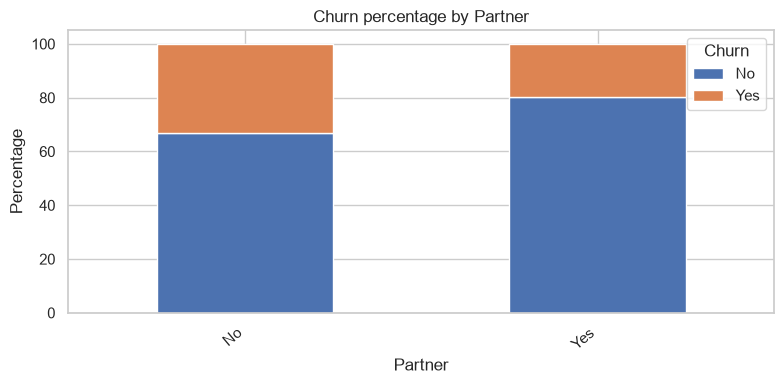


Counts: Dependents vs Churn


Churn,No,Yes,All
Dependents,,,
No,3390,1543,4933
Yes,1784,326,2110
All,5174,1869,7043


Row percentages:


Churn,No,Yes
Dependents,,
No,68.72,31.28
Yes,84.55,15.45


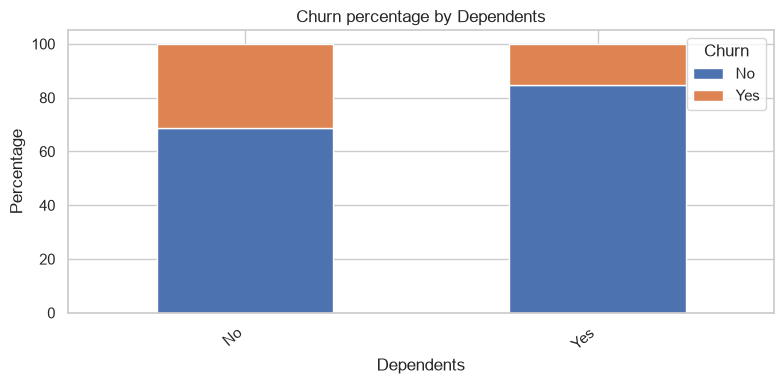


Counts: PhoneService vs Churn


Churn,No,Yes,All
PhoneService,,,
No,512,170,682
Yes,4662,1699,6361
All,5174,1869,7043


Row percentages:


Churn,No,Yes
PhoneService,,
No,75.07,24.93
Yes,73.29,26.71


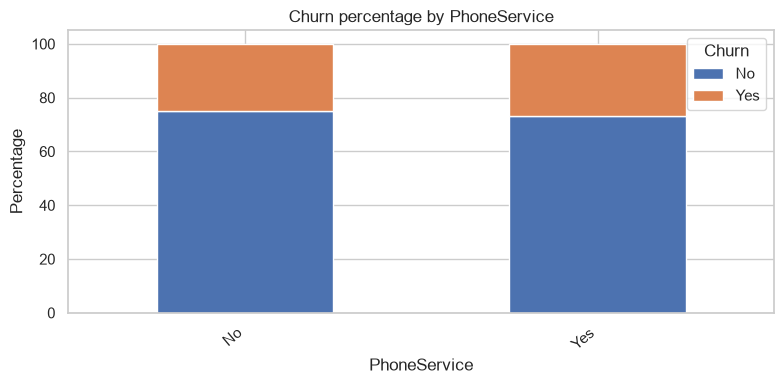


Counts: MultipleLines vs Churn


Churn,No,Yes,All
MultipleLines,,,
No,2541,849,3390
No phone service,512,170,682
Yes,2121,850,2971
All,5174,1869,7043


Row percentages:


Churn,No,Yes
MultipleLines,,
No,74.96,25.04
No phone service,75.07,24.93
Yes,71.39,28.61


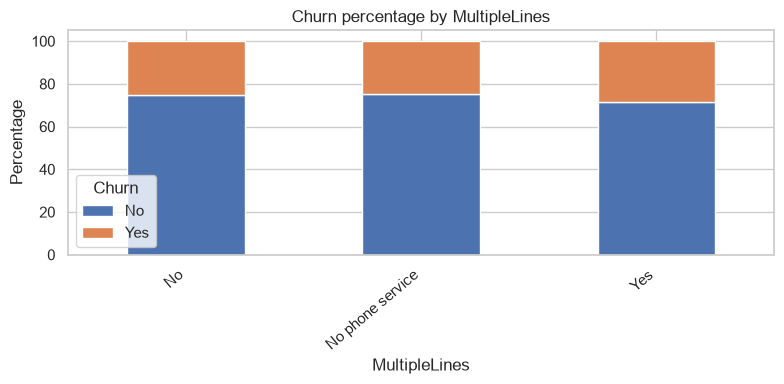


Counts: InternetService vs Churn


Churn,No,Yes,All
InternetService,,,
DSL,1962,459,2421
Fiber optic,1799,1297,3096
No,1413,113,1526
All,5174,1869,7043


Row percentages:


Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


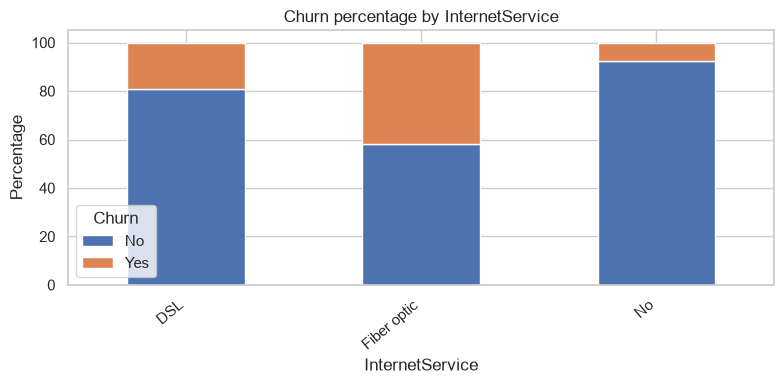


Counts: OnlineSecurity vs Churn


Churn,No,Yes,All
OnlineSecurity,,,
No,2037,1461,3498
No internet service,1413,113,1526
Yes,1724,295,2019
All,5174,1869,7043


Row percentages:


Churn,No,Yes
OnlineSecurity,,
No,58.23,41.77
No internet service,92.60,7.40
Yes,85.39,14.61


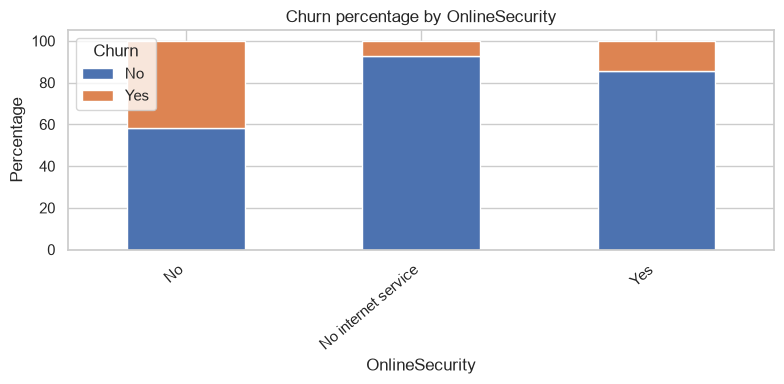


Counts: OnlineBackup vs Churn


Churn,No,Yes,All
OnlineBackup,,,
No,1855,1233,3088
No internet service,1413,113,1526
Yes,1906,523,2429
All,5174,1869,7043


Row percentages:


Churn,No,Yes
OnlineBackup,,
No,60.07,39.93
No internet service,92.60,7.40
Yes,78.47,21.53


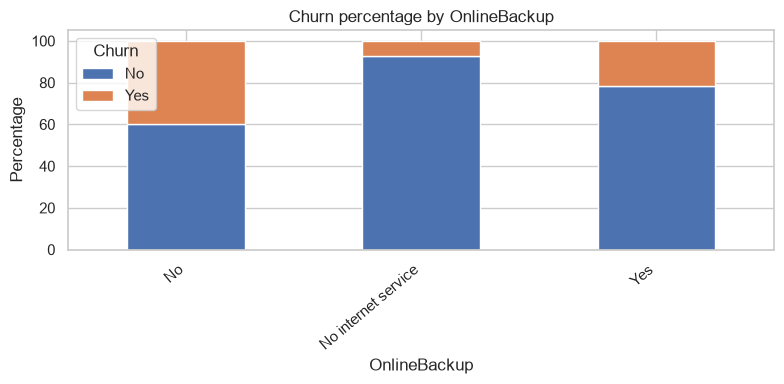


Counts: DeviceProtection vs Churn


Churn,No,Yes,All
DeviceProtection,,,
No,1884,1211,3095
No internet service,1413,113,1526
Yes,1877,545,2422
All,5174,1869,7043


Row percentages:


Churn,No,Yes
DeviceProtection,,
No,60.87,39.13
No internet service,92.60,7.40
Yes,77.50,22.50


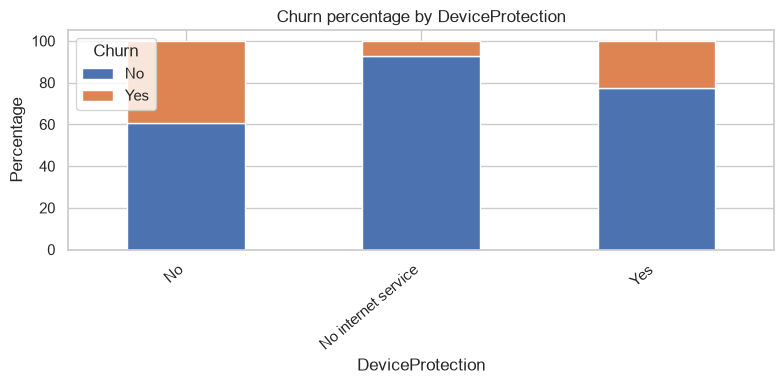


Counts: TechSupport vs Churn


Churn,No,Yes,All
TechSupport,,,
No,2027,1446,3473
No internet service,1413,113,1526
Yes,1734,310,2044
All,5174,1869,7043


Row percentages:


Churn,No,Yes
TechSupport,,
No,58.36,41.64
No internet service,92.60,7.40
Yes,84.83,15.17


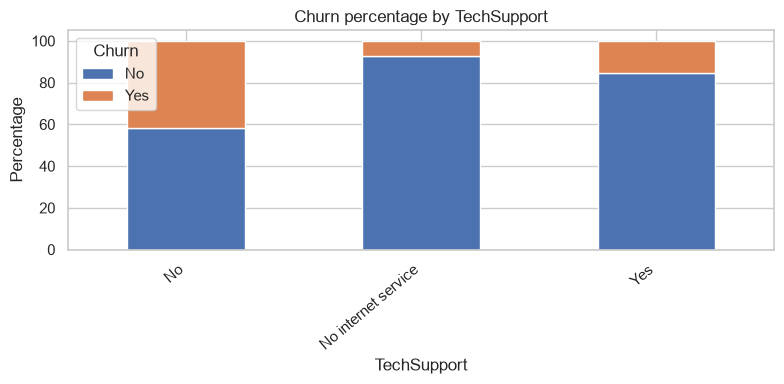


Counts: StreamingTV vs Churn


Churn,No,Yes,All
StreamingTV,,,
No,1868,942,2810
No internet service,1413,113,1526
Yes,1893,814,2707
All,5174,1869,7043


Row percentages:


Churn,No,Yes
StreamingTV,,
No,66.48,33.52
No internet service,92.60,7.40
Yes,69.93,30.07


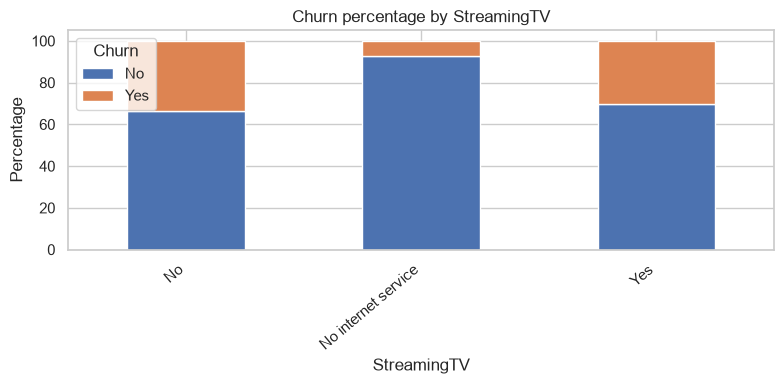


Counts: StreamingMovies vs Churn


Churn,No,Yes,All
StreamingMovies,,,
No,1847,938,2785
No internet service,1413,113,1526
Yes,1914,818,2732
All,5174,1869,7043


Row percentages:


Churn,No,Yes
StreamingMovies,,
No,66.32,33.68
No internet service,92.60,7.40
Yes,70.06,29.94


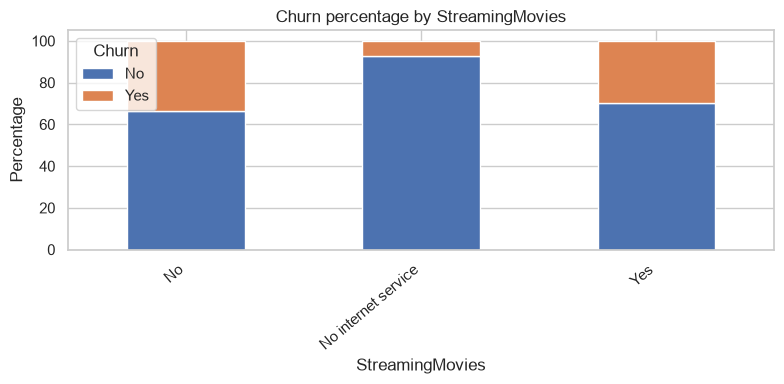


Counts: Contract vs Churn


Churn,No,Yes,All
Contract,,,
Month-to-month,2220,1655,3875
One year,1307,166,1473
Two year,1647,48,1695
All,5174,1869,7043


Row percentages:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


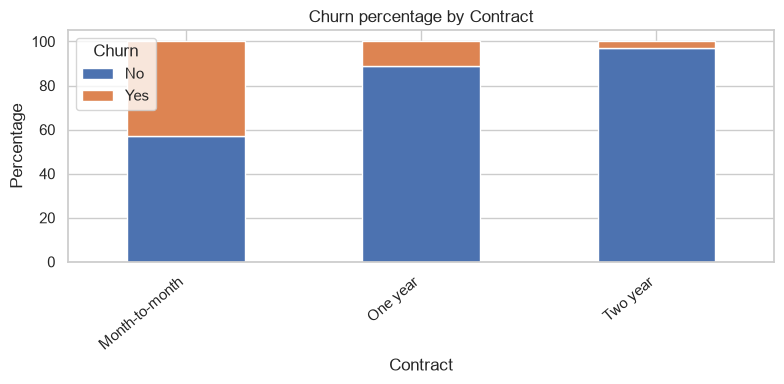


Counts: PaperlessBilling vs Churn


Churn,No,Yes,All
PaperlessBilling,,,
No,2403,469,2872
Yes,2771,1400,4171
All,5174,1869,7043


Row percentages:


Churn,No,Yes
PaperlessBilling,,
No,83.67,16.33
Yes,66.43,33.57


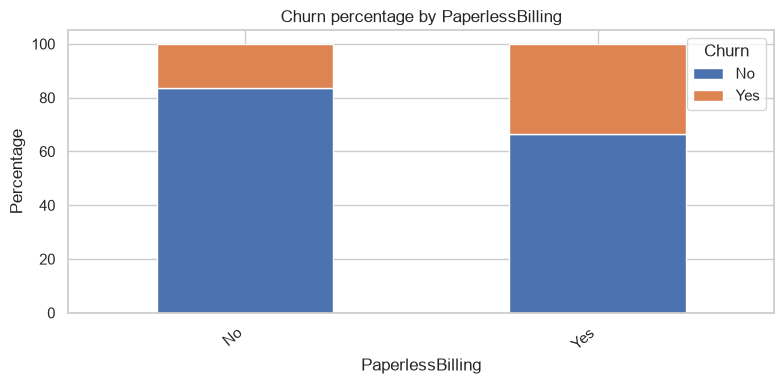


Counts: PaymentMethod vs Churn


Churn,No,Yes,All
PaymentMethod,,,
Bank transfer (automatic),1286,258,1544
Credit card (automatic),1290,232,1522
Electronic check,1294,1071,2365
Mailed check,1304,308,1612
All,5174,1869,7043


Row percentages:


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


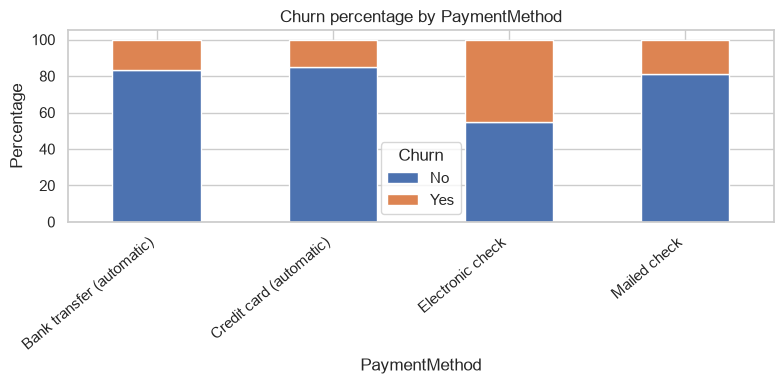

In [8]:
target = "Churn"
if target in df.columns:
    for col in categorical_cols:
        if col == target or col.lower() in {"customerid", "customer_id"}: continue
        if df[col].nunique(dropna=True) > 20:
            print(f"Skipping {col}: too many categories to plot.")
            continue
        print(f"\nCounts: {col} vs {target}")
        display(pd.crosstab(df[col], df[target], margins=True))
        row_pct = pd.crosstab(df[col], df[target], normalize="index")*100
        print("Row percentages:")
        display(row_pct.round(2))
        ax = row_pct.plot(kind="bar", stacked=True, figsize=(8, 4))
        ax.set_title(f"{target} percentage by {col}")
        ax.set_ylabel("Percentage")
        plt.xticks(rotation=40, ha="right")
        plt.tight_layout(); plt.show()
else:
    print("Target column Churn not found.")

## 9. Findings and conclusion
Document:
1. Which variables have low or high cardinality?
2. What are the most and least frequent categories?
3. Which variables contain rare categories?
4. Which variables appear imbalanced?
5. How does churn percentage differ by Contract, PaymentMethod, and InternetService?
6. Which columns are identifiers rather than useful categories?

**Conclusion:** Categorical analysis helps understand group composition, imbalance, rare levels, and encoding considerations. Associations with a target do not prove causation.